# Reviewer analyses from a server snapshot

Run this notebook locally after copying `results/revision-server-snapshot`. It reads the cohort/quality/repeatability reports and completed fold checkpoints from an ongoing real-data run. **No model fitting, threshold tuning, bootstrap recomputation, aggregate classifier performance, significance testing or manuscript import occurs.**

Saved cohort and repeatability audits cover their recorded source population. Completed folds are selected by computation time, so they are unsuitable for final pooled classification estimates. Final analyses remain in Figures-and-Tables.ipynb and manuscript/Reviewer-Evidence.ipynb after the completed server run and completion check.

Derived tables/figures are saved separately under `results/revision-snapshot-analysis/<snapshot-hash>/`. Patient identifiers are present in the copied study artifacts.


In [8]:
from pathlib import Path
import hashlib
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_revision.py").is_file()
)
SNAPSHOT = (
    ROOT / os.environ.get("IIVV_SNAPSHOT", "results/revision-server-snapshot")
).resolve()
INPUTS = {}


def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def tracked(path):
    path = Path(path).resolve()
    if not path.is_relative_to(SNAPSHOT):
        raise ValueError(f"Input is outside the copied snapshot: {path}")
    INPUTS[str(path.relative_to(SNAPSHOT))] = sha(path)
    return path


def jread(path):
    return json.loads(tracked(path).read_text())


def cread(path, **kwargs):
    path = tracked(path)
    try:
        return pd.read_csv(path, **kwargs)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


manifest = jread(SNAPSHOT / "run_manifest.json")
if manifest.get("synthetic") or not manifest.get("input_hashes"):
    raise ValueError(
        "A real-data snapshot with a recorded input inventory is required."
    )
cfg = manifest["config"]
display(
    {
        "snapshot": str(SNAPSHOT),
        "recorded_run_status": manifest["status"],
        "input_summary": manifest.get("input_summary"),
        "folds": cfg["outer_folds"],
        "inner_folds": cfg["inner_folds"],
        "outer_partitions": cfg["outer_repeats"],
    }
)
display(
    Markdown(
        "**Snapshot analysis only. The manifest status is preserved; this notebook does not certify run completion.**"
    )
)

{'snapshot': '/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-server-snapshot',
 'recorded_run_status': 'running',
 'input_summary': {'n_sites': 276,
  'n_patients': 100,
  'n_frequencies': 31,
  'n_patterns': 7728,
  'complex_available': True,
  'unmapped_pathologies': {'leukoplakia': 2,
   'basaloid scc': 1,
   'high-grade adenocarcinoma': 1}},
 'folds': 5,
 'inner_folds': 4,
 'outer_partitions': 1}

**Snapshot analysis only. The manifest status is preserved; this notebook does not certify run completion.**

## 1. Verify completed folds — R1 C1, C7–8, C21; R3 C1

Only folders with complete.json are used. Every listed artifact is checked against its completion hash. A mismatch stops analysis: recopy that complete folder. Incomplete folders are ignored. This inventory checks copied files, not the original server MAT/NPZ inputs or the validity of an unfinished experiment.


In [9]:
execution = jread(SNAPSHOT / "parallel_execution.json")
expected = {(row["task"], tuple(row["key"])) for row in execution["fold_order"]}
known_sources = [manifest["source_hashes"]]
for parent in SNAPSHOT.glob("resume-parent-*.json"):
    known_sources.append(jread(parent)["source_hashes"])
FOLDS, inventory, task_inventories = [], [], {}
required = {
    "splits.json",
    "selections.json",
    "candidate_failures.json",
    "outer_predictions.csv",
    "inner_search.csv",
    "task_inclusion.csv",
    "task_label_audit.csv",
    "classes.json",
}
for marker_path in sorted((SNAPSHOT / "fold-checkpoints").glob("*/*/complete.json")):
    marker = jread(marker_path)
    folder = marker_path.parent
    identity = (marker["task"], tuple(marker["fold_key"]))
    if identity not in expected or marker["task"] != folder.parent.name:
        raise ValueError(f"Unexpected fold identity: {folder}")
    if not required <= set(marker["artifacts"]):
        raise ValueError(f"Incomplete checkpoint inventory: {folder}")
    if marker.get("source_version", {}).get("hashes") not in known_sources:
        raise ValueError(
            "Unknown checkpoint source version; copy its matching resume-parent manifest."
        )
    for relative, recorded_hash in marker["artifacts"].items():
        path = (folder / relative).resolve()
        if not path.is_relative_to(folder.resolve()) or sha(path) != recorded_hash:
            raise ValueError(
                f"Checkpoint hash mismatch: {path}; recopy this completed fold."
            )
        tracked(path)
    previous = task_inventories.setdefault(
        marker["task"], marker["artifacts"]["task_inclusion.csv"]
    )
    if previous != marker["artifacts"]["task_inclusion.csv"]:
        raise ValueError("Different task inclusion inventories in one snapshot.")
    FOLDS.append((folder, marker))
    inventory.append(
        {
            "task": marker["task"],
            "repeat": marker["fold_key"][0],
            "outer_fold": marker["fold_key"][1],
            "evaluation": marker["fold_key"][2],
            "elapsed_hours": marker["elapsed_seconds"] / 3600,
            "checkpoint": str(folder),
        }
    )
if len({(m["task"], tuple(m["fold_key"])) for _, m in FOLDS}) != len(FOLDS):
    raise ValueError("Duplicate completed fold identities.")
SNAPSHOT_HASH = hashlib.sha256(json.dumps(INPUTS, sort_keys=True).encode()).hexdigest()
OUT = ROOT / "results/revision-snapshot-analysis" / SNAPSHOT_HASH[:12]
OUT.mkdir(parents=True, exist_ok=True)


def table(frame, name):
    if not isinstance(frame, pd.DataFrame):
        frame = pd.DataFrame(frame)
    frame.to_csv(OUT / (name + ".csv"), index=False)
    display(Markdown(f"**{name}** — {len(frame)} rows; the CSV contains all rows."))
    display(frame.head(30))
    return frame


def figure(fig, name):
    for suffix in ("png", "pdf"):
        fig.savefig(OUT / (name + "." + suffix), dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


table(
    pd.DataFrame(
        inventory,
        columns=[
            "task",
            "repeat",
            "outer_fold",
            "evaluation",
            "elapsed_hours",
            "checkpoint",
        ],
    ),
    "copied-completed-folds",
)
display(
    {
        "completed_folds_copied": len(FOLDS),
        "scheduled_folds": len(expected),
        "derived_output_directory": str(OUT),
    }
)

**copied-completed-folds** — 9 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,elapsed_hours,checkpoint
0,cancer_vs_lr_hr,0,0,nested_cv,7.621610,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
1,cancer_vs_lr_hr,0,2,nested_cv,35.739067,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
2,cancer_vs_lr_hr,0,3,nested_cv,18.298971,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
3,cancer_vs_lr_hr,0,4,nested_cv,33.063273,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
4,healthy_vs_cancer,0,1,nested_cv,6.998435,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
5,healthy_vs_cancer,0,2,nested_cv,9.481813,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
6,healthy_vs_cancer,0,3,nested_cv,14.931912,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
7,highrisk_vs_lowrisk,0,0,nested_cv,18.989594,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
8,highrisk_vs_lowrisk,0,2,nested_cv,37.131659,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...


{'completed_folds_copied': 9,
 'scheduled_folds': 20,
 'derived_output_directory': '/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-snapshot-analysis/56d01539e5e6'}

## 2. Cohort, labels and available demographics — R1 C10–14, M6; R2 C3

Samples are measurement sites. A patient can contribute multiple tissue classes or locations; do not sum patient counts across such strata. These tables describe the full saved source audit, including unmapped diagnoses, before task-specific exclusion. Missing demographic values are reported rather than imputed.


**source-pathology-counts** — 5 rows; the CSV contains all rows.

,pathology,n_samples,n_patients
0,Cancer,96,70
1,Healthy,100,95
2,High-grade dysplasia,32,21
3,Non-malignant,44,28
4,Unmapped / excluded,4,4


**raw-pathology-counts** — 13 rows; the CSV contains all rows.

,pathology,raw_pathology,n_samples,n_patients
0,Cancer,invasive carcinoma,96,70
1,Healthy,healthy,100,95
2,High-grade dysplasia,cis,5,4
3,High-grade dysplasia,high grade dysplasia,2,2
4,High-grade dysplasia,high-grade dysplasia,8,7
5,High-grade dysplasia,high-grade dysplasia /cis,1,1
6,High-grade dysplasia,high-grade dysplasia/ cis,8,4
7,High-grade dysplasia,moderate dysplasia,8,7
8,Non-malignant,benign,33,20
9,Non-malignant,mild dysplasia,11,8


**samples-per-patient** — 8 rows; the CSV contains all rows.

...

,variable,available
0,prior_radiation,True
1,location,True
2,prior_surgery,True
3,age,False
4,sex,False
5,smoking,False
6,alcohol,False
7,inflammation,False
8,treatment_history,False
9,contact_pressure,False


**available-categorical-demographics** — 87 rows; the CSV contains all rows.

,variable,pathology,value,n_samples,n_patients
0,prior_radiation,Cancer,<missing>,11,6
1,prior_radiation,Cancer,No,77,58
2,prior_radiation,Cancer,Yes,8,6
3,prior_radiation,Healthy,<missing>,8,8
4,prior_radiation,Healthy,No,82,77
5,prior_radiation,Healthy,Yes,10,10
6,prior_radiation,High-grade dysplasia,No,27,18
7,prior_radiation,High-grade dysplasia,Yes,5,3
8,prior_radiation,Non-malignant,<missing>,12,5
9,prior_radiation,Non-malignant,No,29,21


**pathology-by-location** — 5 rows; the CSV contains all rows.

location,pathology,<missing>,alveolar ridge,anterior tongue,base tongue,buccal margin,buccal mucosa,floor of mouth,floor of the mouth,gingival mucosa,...,retromolar trigone / palate,right anterior tongue,right buccal mucosa,right retromolar trigone,right soft palate,soft palate,tonsil,tonsillar pillar,upper lip,ventral tongue
0,Cancer,0,3,0,9,0,3,1,15,2,...,0,0,0,0,0,1,16,0,1,1
1,Healthy,1,0,0,4,0,34,0,5,2,...,0,1,2,1,1,6,12,1,0,0
2,High-grade dysplasia,0,0,0,0,0,3,0,3,0,...,0,0,0,0,0,0,1,1,0,0
3,Non-malignant,0,0,1,2,1,4,0,3,0,...,0,0,0,0,0,2,1,0,0,2
4,Unmapped / excluded,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0


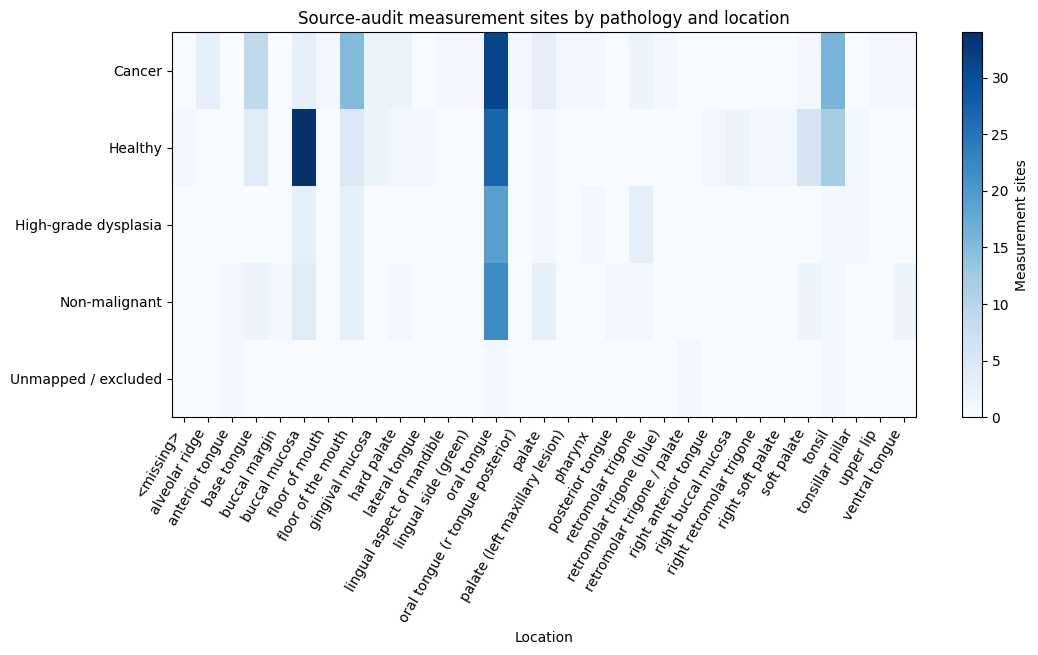

In [10]:
sites = cread(
    SNAPSHOT / "quality/site_inclusion_audit.csv",
    dtype={"patient_id": str, "sample_id": str, "site_id": str},
)
if not sites.sample_id.is_unique:
    raise ValueError("Duplicate source-audit sample identifiers.")
cohort = sites.assign(pathology=sites.pathology.fillna("Unmapped / excluded"))
counts = (
    cohort.groupby("pathology", dropna=False)
    .agg(n_samples=("sample_id", "size"), n_patients=("patient_id", "nunique"))
    .reset_index()
)
table(counts, "source-pathology-counts")
raw_counts = (
    cohort.groupby(["pathology", "raw_pathology"], dropna=False)
    .agg(n_samples=("sample_id", "size"), n_patients=("patient_id", "nunique"))
    .reset_index()
)
table(raw_counts, "raw-pathology-counts")
sizes = cohort.groupby("patient_id").size()
table(
    sizes.value_counts()
    .sort_index()
    .rename_axis("samples_per_patient")
    .reset_index(name="n_patients"),
    "samples-per-patient",
)
clinical = jread(SNAPSHOT / "quality/clinical_metadata_status.json")
table(
    [{"variable": col, "available": True} for col in clinical["available"]]
    + [{"variable": col, "available": False} for col in clinical["missing"]],
    "clinical-field-availability",
)
demographics = []
for column in clinical["available"]:
    if column not in cohort:
        continue
    if pd.api.types.is_numeric_dtype(cohort[column]):
        continue  # actual per-patient numeric distributions are not guessed from categorical reports
    view = cohort.assign(value=cohort[column].fillna("<missing>").astype(str))
    for (pathology, value), group in view.groupby(["pathology", "value"], dropna=False):
        demographics.append(
            {
                "variable": column,
                "pathology": pathology,
                "value": value,
                "n_samples": len(group),
                "n_patients": group.patient_id.nunique(),
            }
        )
table(demographics, "available-categorical-demographics")
if "location" in cohort:
    anatomy = pd.crosstab(cohort.pathology, cohort.location.fillna("<missing>"))
    table(anatomy.reset_index(), "pathology-by-location")
    fig, ax = plt.subplots(figsize=(12, 5))
    image = ax.imshow(anatomy.to_numpy(), aspect="auto", cmap="Blues")
    ax.set_xticks(range(len(anatomy.columns)), anatomy.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(anatomy.index)), anatomy.index)
    ax.set(
        title="Source-audit measurement sites by pathology and location",
        xlabel="Location",
    )
    fig.colorbar(image, ax=ax, label="Measurement sites")
    figure(fig, "pathology-by-location")

## 3. Signal-quality filtering and class/location bias — R1 C2–5, C13–14

These are saved quality audits, not classifier performance. The strict cutoff rule is missing_percent < cutoff; 100.000001 includes every valid 0–100 score. Retained-site percentages and demographic composition cannot establish that a cutoff is diagnostically safe. Existing association p values are displayed as recorded; no statistical test is rerun.


**quality-retention-by-class** — 20 rows; the CSV contains all rows.

,cutoff,class_name,n_total_sites,n_retained_sites,n_total_patients,n_retained_patients,retained_site_percent
0,40.000000,Cancer,96,96,70,70,100.000000
1,40.000000,Healthy,100,75,95,74,75.000000
2,40.000000,High-grade dysplasia,32,26,21,17,81.250000
3,40.000000,Non-malignant,44,40,28,26,90.909091
4,40.000000,Unmapped / excluded,4,2,4,2,50.000000
5,60.000000,Cancer,96,96,70,70,100.000000
6,60.000000,Healthy,100,90,95,88,90.000000
7,60.000000,High-grade dysplasia,32,29,21,19,90.625000
8,60.000000,Non-malignant,44,41,28,27,93.181818
9,60.000000,Unmapped / excluded,4,4,4,4,100.000000


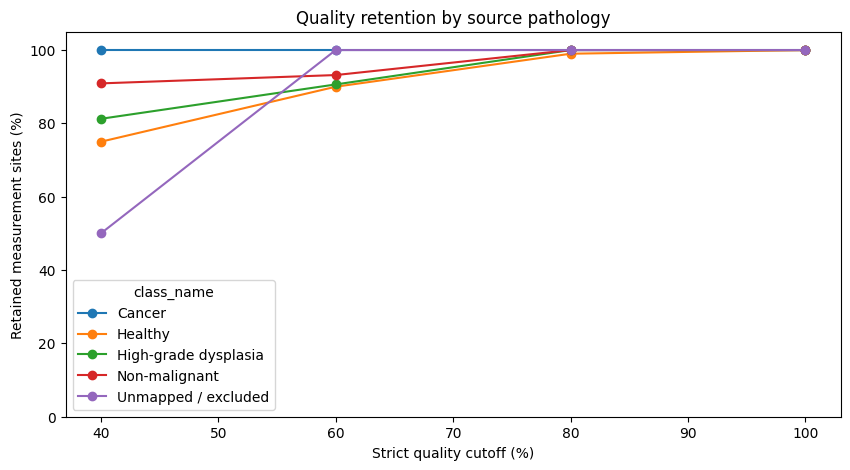

**missing_patterns_by_class** — 5 rows; the CSV contains all rows.

,pathology,count,mean,std,min,median,max
0,Cancer,96,6.095911,6.661122,1.690821,3.040890,31.983264
1,Healthy,100,25.667001,22.377060,2.057453,17.494824,93.672360
2,High-grade dysplasia,32,24.899715,21.077964,2.980504,19.636387,77.329193
3,Non-malignant,44,17.214948,18.136163,2.126467,9.758885,70.445135
4,NaN,4,30.704365,25.075960,2.355072,30.372239,59.717909


**missing_patterns_by_class_location** — 61 rows; the CSV contains all rows.

,pathology,location,count,mean,std
0,Cancer,alveolar ridge,3,2.415459,0.604834
1,Cancer,base tongue,9,5.652366,5.423205
2,Cancer,buccal mucosa,3,2.914366,0.284625
3,Cancer,floor of mouth,1,2.014320,NaN
4,Cancer,floor of the mouth,15,4.520646,3.859887
5,Cancer,gingival mucosa,2,3.506729,1.866586
6,Cancer,hard palate,2,2.680728,0.796044
7,Cancer,lingual aspect of mandible,1,2.251553,NaN
8,Cancer,lingual side (green),1,10.718599,NaN
9,Cancer,oral tongue,31,7.060765,7.265740


**quality_cluster_associations** — 3 rows; the CSV contains all rows.

...

,variable,level,status,wald_chi2,df,p_value,n_patients,method,reason,n_coefficients,covariance_rank,p_holm
0,prior_radiation,No,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
1,prior_radiation,Yes,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
2,location,oral tongue,computed,15.391316,3.0,1.511015e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.137452e-02
3,location,base tongue,computed,9.982849,3.0,1.871249e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.987996e-01
4,location,floor of the mouth,computed,5.576719,3.0,1.341213e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
5,location,anterior tongue,unavailable,NaN,NaN,NaN,100,NaN,singular or ill-conditioned patient-cluster co...,3.0,1.0,NaN
6,location,tonsil,computed,11.527527,3.0,9.190010e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,3.032703e-01
7,location,buccal mucosa,computed,38.233536,3.0,2.522313e-08,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.828097e-07
8,location,soft palate,computed,9.183887,3.0,2.694333e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.352432e-01
9,location,palate,computed,4.859811,3.0,1.823550e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00


**missingness_encoding_audit.json**

{'max_reported_vs_observed_difference': 36.15424430641822,
 'n_sites_disagreeing_by_more_than_one_percentage_point': 209,
 'note': 'Observed missing patterns have any non-finite frequency. Avg_Cutpats may be averaged over repeated acquisitions; discrepancies need upstream audit.'}

**source_quality_audit.json**

{'n_sites': 276,
 'all_reported_quality_equals_mean_of_test_quality': True,
 'max_quality_mean_abs_difference': 0.0,
 'n_exported_spectra_equal_nanmean_of_test_means': 276,
 'interpretation': 'Reported Avg_Cutpats is checked against the arithmetic mean of the supplied per-test rejection percentages. Missingness of the final averaged spectrum is a different quantity. This does not reconstruct within-burst filtering or contact controls.',
 'mat_sha256': 'c05c8082b3958df369d2a62abb2b9dfbe6eab8e7a511d339e1f139599c0e832c',
 'script_sha256': 'ce0bac5b3efe55098f2aff2c93fc28b09c70f5341587043d17d9339cbfecb484'}

In [11]:
retention = cread(SNAPSHOT / "quality/retention_by_threshold_class.csv")
retention["class_name"] = retention.class_name.fillna("Unmapped / excluded")
retention["retained_site_percent"] = (
    100 * retention.n_retained_sites / retention.n_total_sites
)
table(retention, "quality-retention-by-class")
curve = retention.pivot(
    index="cutoff", columns="class_name", values="retained_site_percent"
)
ax = curve.plot(
    marker="o",
    figsize=(10, 5),
    ylim=(0, 105),
    ylabel="Retained measurement sites (%)",
    xlabel="Strict quality cutoff (%)",
)
ax.set_title("Quality retention by source pathology")
figure(ax.figure, "quality-retention")
for name in (
    "missing_patterns_by_class",
    "missing_patterns_by_class_location",
    "quality_cluster_associations",
    "covariate_cluster_associations",
):
    path = SNAPSHOT / "quality" / (name + ".csv")
    if path.is_file():
        table(cread(path), name)
for name in ("missingness_encoding_audit.json", "source_quality_audit.json"):
    path = SNAPSHOT / "quality" / name
    if path.is_file():
        display(Markdown("**" + name + "**"))
        display(jread(path))

## 4. Repositioned test-mean repeatability — R1 C24–25

Display the saved coordinate/scalar variability and ICC(2,1) intervals without rerunning bootstrap. Read the stored endpoint and exclusions: the available test means do not recover the nine individual bursts, controlled pressure/angle experiments or pathology registration.


{'status': 'computed',
 'icc_endpoint': 'mean magnitude over available frequencies and patterns per acquisition replicate',
 'icc_model': 'ICC(2,1), absolute agreement; first three available test positions, complete sites; patient-cluster intervals',
 'n_replicates': 4,
 'caveat': 'Only supplied replicate units are analyzed. The two to four MATLAB Full_data spectra are test means, not nine bursts; within-burst repeatability is unavailable. Multiple sites within patients are clustered for intervals.'}

**saved-icc-and-patient-bootstrap-intervals** — 5 rows; the CSV contains all rows.

,class_name,n_sites,icc_2_1_absolute,balanced_icc_sites,balanced_icc_replicates,icc_ci_low,icc_ci_high,valid_cluster_bootstraps,between_site_sd
0,All,276,0.915723,274,3,0.886939,0.939942,1000,252.803002
1,Healthy,100,0.851177,100,3,0.774169,0.908951,1000,201.405185
2,Cancer,96,0.931818,95,3,0.890645,0.956170,1000,170.761702
3,Non-malignant,44,0.802229,44,3,0.577712,0.926342,1000,213.357189
4,High-grade dysplasia,32,0.877517,31,3,0.709385,0.954505,1000,233.354006


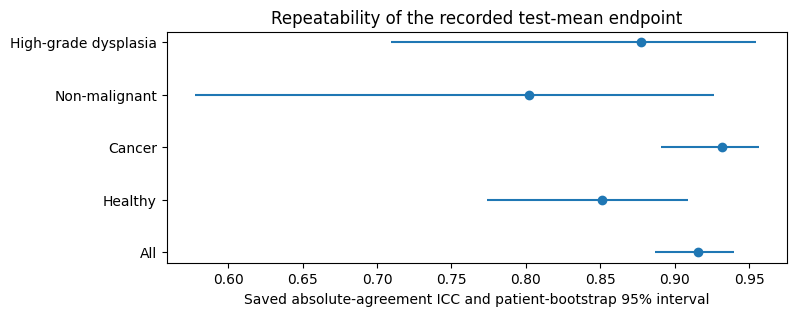

**saved-site-repeatability-by-pathology** — 5 rows; the CSV contains all rows.

,pathology,n_samples,n_patients,mean_coordinate_cv,mean_scalar_repeat_cv,mean_repositioning_sd
0,Cancer,96,70,0.267598,0.103617,29.952888
1,Healthy,100,95,0.279574,0.106500,62.716906
2,High-grade dysplasia,32,21,0.309234,0.113051,61.131842
3,Non-malignant,44,28,0.308480,0.139748,71.675798
4,NaN,4,4,0.312125,0.098415,54.436626


In [12]:
repeat_status = jread(SNAPSHOT / "repeatability/status.json")
display(repeat_status)
icc_path = SNAPSHOT / "repeatability/icc_and_inter_site_variability.csv"
if icc_path.is_file():
    icc = cread(icc_path)
    table(icc, "saved-icc-and-patient-bootstrap-intervals")
    finite = icc[["icc_2_1_absolute", "icc_ci_low", "icc_ci_high"]].notna().all(axis=1)
    shown = icc.loc[finite].reset_index(drop=True)
    if len(shown):
        fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(shown))))
        for i, row in shown.iterrows():
            ax.plot(row.icc_2_1_absolute, i, "o", color="tab:blue")
            ax.hlines(i, row.icc_ci_low, row.icc_ci_high, color="tab:blue")
        ax.set_yticks(range(len(shown)), shown.class_name)
        ax.set(
            xlabel="Saved absolute-agreement ICC and patient-bootstrap 95% interval",
            title="Repeatability of the recorded test-mean endpoint",
        )
        figure(fig, "saved-test-mean-icc")
site_repeat_path = SNAPSHOT / "repeatability/site_repeatability.csv"
if site_repeat_path.is_file():
    repeat = cread(site_repeat_path, dtype={"patient_id": str, "sample_id": str})
    table(
        repeat.groupby("pathology", dropna=False)
        .agg(
            n_samples=("sample_id", "size"),
            n_patients=("patient_id", "nunique"),
            mean_coordinate_cv=("mean_coordinate_cv", "mean"),
            mean_scalar_repeat_cv=("scalar_repeat_cv", "mean"),
            mean_repositioning_sd=("repositioning_sd", "mean"),
        )
        .reset_index(),
        "saved-site-repeatability-by-pathology",
    )

## 5. Completed-fold partitions, pathology and coverage — R1 C1–3, C7–8, C10, M6; R3 C1

These tables cover only copied completed folds. They verify patient separation, inner-fit provenance and training-only postprocessing, and describe inclusion/quality coverage. They do not summarize diagnostic discrimination, select a winner or extrapolate missing folds. No ROC/AUC/F1/SN/SP/PPV/NPV estimates or confidence intervals are computed from the incomplete fold set.


In [13]:
population_rows, pathology_rows, coverage_rows, failure_rows = [], [], [], []
for folder, marker in FOLDS:
    inclusion = cread(
        folder / "task_inclusion.csv", dtype={"patient_id": str, "sample_id": str}
    )
    classes = jread(folder / "classes.json")["classes"]
    inclusion["task_class"] = inclusion.class_index.map(dict(enumerate(classes)))
    if not inclusion.sample_id.is_unique:
        raise ValueError(f"Duplicate task inclusion IDs: {folder}")
    splits = jread(folder / "splits.json")
    if len(splits) != 1:
        raise ValueError(f"Expected exactly one split in {folder}")
    split = splits[0]
    actual_key = (split["repeat"], split["outer_fold"], split["evaluation"])
    if actual_key != tuple(marker["fold_key"]):
        raise ValueError("Split and completion marker identities disagree.")
    train, test = set(split["train_patients"]), set(split["test_patients"])
    if train & test or len(split["inner"]) != cfg["inner_folds"]:
        raise ValueError("Invalid outer partition or inner-fold count.")
    roles = [
        (-1, "outer_train", split["train_sample_ids"]),
        (-1, "outer_test", split["test_sample_ids"]),
    ]
    for inner_fold, inner in enumerate(split["inner"]):
        a, b = set(inner["train_patients"]), set(inner["validation_patients"])
        if a & b or a | b != train:
            raise ValueError("Invalid inner patient partition.")
        roles.extend(
            [
                (inner_fold, "inner_train", inner["train_sample_ids"]),
                (inner_fold, "inner_validation", inner["validation_sample_ids"]),
            ]
        )
    base = {
        "task": marker["task"],
        "repeat": split["repeat"],
        "outer_fold": split["outer_fold"],
        "evaluation": split["evaluation"],
    }
    for inner_fold, role, sample_ids in roles:
        members = inclusion.set_index("sample_id").loc[sample_ids].reset_index()
        for cutoff in [None, *sorted(set(cfg["cutoffs"] + [cfg["default_cutoff"]]))]:
            retained = (
                members if cutoff is None else members[members.missing_percent < cutoff]
            )
            identity = {
                **base,
                "inner_fold": inner_fold,
                "partition": role,
                "population": "unfiltered" if cutoff is None else "quality_retained",
                "cutoff": cutoff,
            }
            population_rows.append(
                {
                    **identity,
                    "n_samples": len(retained),
                    "n_patients": retained.patient_id.nunique(),
                    "n_quality_excluded_sites": len(members) - len(retained),
                }
            )
            for (label, raw), group in retained.groupby(
                ["task_class", "raw_pathology"], dropna=False
            ):
                pathology_rows.append(
                    {
                        **identity,
                        "task_class": label,
                        "raw_pathology": raw,
                        "n_samples": len(group),
                        "n_patients": group.patient_id.nunique(),
                    }
                )
    for selection in jread(folder / "selections.json"):
        fit_ids = set(selection["postprocessing_fit_sample_ids"])
        if (
            not fit_ids <= set(split["train_sample_ids"])
            or set(selection["postprocessing_fit_patient_ids"]) - train
        ):
            raise ValueError(
                "Postprocessing provenance crosses the outer training boundary."
            )
        fits = selection["inner_fit_provenance"]
        if len(fits) != len(split["inner"]):
            raise ValueError("Missing inner-fit provenance.")
        for fit, inner in zip(fits, split["inner"]):
            if not set(fit["train_patients"]) <= set(inner["train_patients"]) or set(
                fit["test_patients"]
            ) != set(inner["validation_patients"]):
                raise ValueError("Inner fit crosses its recorded training boundary.")
    predictions = cread(
        folder / "outer_predictions.csv", dtype={"patient_id": str, "sample_id": str}
    )
    for stream, group in predictions.groupby("stream"):
        if (
            set(group.sample_id) != set(split["test_sample_ids"])
            or group.sample_id.duplicated().any()
        ):
            raise ValueError("Incomplete or duplicate test coverage.")
        if not group.covered.isin([True, False]).all():
            raise ValueError("Invalid covered flags.")
        coverage_rows.append(
            {
                **base,
                "stream": stream,
                "n_samples": len(group),
                "n_patients": group.patient_id.nunique(),
                "n_covered": int(group.covered.sum()),
                "site_coverage": float(group.covered.mean()),
            }
        )
    for failure in jread(folder / "candidate_failures.json"):
        failure_rows.append(
            {
                **base,
                "reason": failure["reason"],
                "candidate": json.dumps(failure["candidate"], sort_keys=True),
            }
        )
table(population_rows, "completed-fold-populations")
table(pathology_rows, "completed-fold-raw-pathology")
table(coverage_rows, "completed-fold-quality-coverage")
table(failure_rows, "completed-fold-candidate-failures")

**completed-fold-populations** — 450 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,inner_fold,partition,population,cutoff,n_samples,n_patients,n_quality_excluded_sites
0,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,140,78,0
1,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,quality_retained,40.000000,132,75,8
2,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,quality_retained,60.000000,135,76,5
3,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,quality_retained,80.000000,140,78,0
4,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,quality_retained,100.000001,140,78,0
5,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_test,unfiltered,NaN,32,19,0
6,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_test,quality_retained,40.000000,30,18,2
7,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_test,quality_retained,60.000000,31,19,1
8,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_test,quality_retained,80.000000,32,19,0
9,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_test,quality_retained,100.000001,32,19,0


**completed-fold-raw-pathology** — 2603 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,inner_fold,partition,population,cutoff,task_class,raw_pathology,n_samples,n_patients
0,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Cancer,invasive carcinoma,78,57
1,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,cis,5,4
2,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high grade dysplasia,2,2
3,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high-grade dysplasia,6,5
4,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high-grade dysplasia /cis,1,1
5,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high-grade dysplasia/ cis,7,3
6,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,moderate dysplasia,6,5
7,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Non-malignant,benign,27,16
8,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Non-malignant,mild dysplasia,8,6
9,cancer_vs_lr_hr,0,0,nested_cv,-1,outer_train,quality_retained,40.0,Cancer,invasive carcinoma,78,57


**completed-fold-quality-coverage** — 396 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,stream,n_samples,n_patients,n_covered,site_coverage
0,cancer_vs_lr_hr,0,0,nested_cv,ablation_imputation_mean,32,19,31,0.96875
1,cancer_vs_lr_hr,0,0,nested_cv,ablation_imputation_median,32,19,31,0.96875
2,cancer_vs_lr_hr,0,0,nested_cv,ablation_imputation_zero,32,19,31,0.96875
3,cancer_vs_lr_hr,0,0,nested_cv,ablation_missingness,32,19,31,0.96875
4,cancer_vs_lr_hr,0,0,nested_cv,ablation_normalization_freq,32,19,31,0.96875
5,cancer_vs_lr_hr,0,0,nested_cv,ablation_normalization_global,32,19,31,0.96875
6,cancer_vs_lr_hr,0,0,nested_cv,ablation_normalization_none,32,19,31,0.96875
7,cancer_vs_lr_hr,0,0,nested_cv,ablation_quality_100.000001,32,19,32,1.00000
8,cancer_vs_lr_hr,0,0,nested_cv,ablation_quality_40,32,19,30,0.93750
9,cancer_vs_lr_hr,0,0,nested_cv,ablation_quality_60,32,19,31,0.96875


**completed-fold-candidate-failures** — 0 rows; the CSV contains all rows.

""


""


## 6. Evidence provenance and next steps

The exports are supporting cohort/quality/repeatability and implementation evidence. Fold-derived tables remain preliminary. Final discrimination, corrected CV tests, comparisons and manuscript numerical imports wait for all scheduled folds and the completed-run check. Recopy new completed folds and rerun this notebook to obtain a new snapshot directory. If the manifest records a resumed run, also transfer its resume-parent manifests.

Do not change the original manifest status or disable the completion guards in the final-result notebooks.


In [14]:
provenance = {
    "kind": "server snapshot analysis; no final classification inference",
    "snapshot": str(SNAPSHOT),
    "snapshot_hash": SNAPSHOT_HASH,
    "recorded_run_status": manifest["status"],
    "scheduled_folds": len(expected),
    "copied_completed_folds": len(FOLDS),
    "classification_metrics_aggregated": False,
    "fitting_or_resampling_performed": False,
    "input_artifact_sha256": INPUTS,
    "output_artifact_sha256": {
        p.name: sha(p)
        for p in sorted(OUT.iterdir())
        if p.is_file() and p.name != "snapshot-provenance.json"
    },
}
(OUT / "snapshot-provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
display(Markdown(f"Tables and PDF/PNG figures saved to **{OUT.relative_to(ROOT)}**."))
display(pd.DataFrame({"file": sorted(p.name for p in OUT.iterdir())}))

Tables and PDF/PNG figures saved to **results/revision-snapshot-analysis/56d01539e5e6**.

,file
0,available-categorical-demographics.csv
1,clinical-field-availability.csv
2,completed-fold-candidate-failures.csv
3,completed-fold-populations.csv
4,completed-fold-quality-coverage.csv
5,completed-fold-raw-pathology.csv
6,copied-completed-folds.csv
7,covariate_cluster_associations.csv
8,missing_patterns_by_class.csv
9,missing_patterns_by_class_location.csv
